# Task 4: Location-Based Analysis of Restaurants

**Author:** [Pradeep Srinivas B]  |  **Program:** Cognifyz Technologies, Data Science Internship  |  **Date:** [October 2026]

## Objective
Analyze the geographical distribution of restaurants, compare cities and localities, identify cuisine concentrations, and measure how price range relates to customer ratings.

## Executive Summary
- The dataset covers **9,551 restaurants in 141 cities**, but **80.3%** are in New Delhi, Gurgaon, and Noida, so findings mainly describe Delhi-NCR.
- **North Indian, Chinese, and Fast Food** are the leading cuisines in all three major cities.
- **Sector 29 (Gurgaon)** has the highest average rating among Delhi-NCR localities with at least 10 rated restaurants (3.89), closely followed by Cyber Hub (3.86).
- Among rated restaurants, higher price ranges are **moderately associated with higher ratings** (r = 0.40).
- Two data-quality issues were corrected: **497 placeholder (0, 0) coordinates** and **2,148 unrated restaurants** (rating 0). Ignoring them would distort maps and rating comparisons.

## Contents
1. Data Loading and Inspection
2. Data Validation and Cleaning
3. Global Restaurant Distribution
4. Delhi-NCR Concentration
5. City-Level Analysis
6. Cuisine Distribution
7. Locality-Level Analysis
8. Delhi-NCR Locality Comparison
9. Price Range and Ratings
10. Summary Statistics and Conclusion

## 1. Data Loading and Inspection

**Purpose:** Load the restaurant dataset and check its size, missing values, and duplicates before any analysis.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# Look for the dataset in Colab's /content folder first, then the current folder
search_dirs = ["/content", "."]
csv_path = None
for d in search_dirs:
    if os.path.isdir(d):
        found = sorted(f for f in os.listdir(d) if f.lower().endswith(".csv"))
        if found:
            csv_path = os.path.join(d, found[0])
            break

if csv_path is None:
    raise FileNotFoundError(
        "No CSV file found. Upload the restaurant dataset using the Files panel and re-run this cell."
    )

df = pd.read_csv(csv_path)

print("File:", csv_path)
print("Shape:", df.shape)
print("\nMissing values (columns with gaps only):")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
display(df.head())

File: /content/Dataset .csv
Shape: (9551, 21)

Missing values (columns with gaps only):
Cuisines    9
dtype: int64

Duplicate rows: 0


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## 2. Data Validation and Cleaning

**Purpose:** Make sure location and rating data can be trusted before analysis.

**Method:**
1. Convert coordinates to numbers and flag missing values.
2. Flag values outside the valid latitude (-90 to 90) and longitude (-180 to 180) range.
3. Flag `(0, 0)` coordinates. They pass the range check but point to the ocean off West Africa, so they are placeholders for unknown locations.
4. Flag ratings of `0`, which mean the restaurant has not been rated yet. Treating them as real scores would unfairly lower averages.

Two working datasets are created: `map_df` (usable coordinates) and `rated_df` (rated restaurants).

In [2]:
geo_df = df.copy()
geo_df["Latitude"] = pd.to_numeric(geo_df["Latitude"], errors="coerce")
geo_df["Longitude"] = pd.to_numeric(geo_df["Longitude"], errors="coerce")

missing_mask = geo_df["Latitude"].isna() | geo_df["Longitude"].isna()
out_of_range_mask = (
    ~geo_df["Latitude"].between(-90, 90) | ~geo_df["Longitude"].between(-180, 180)
) & ~missing_mask
zero_mask = (geo_df["Latitude"] == 0) & (geo_df["Longitude"] == 0)

geo_df["Valid_Coords"] = ~(missing_mask | out_of_range_mask | zero_mask)

# Rating of 0 = not rated yet
geo_df["Is_Rated"] = geo_df["Aggregate rating"] > 0

print("=" * 60)
print("GEOGRAPHICAL DATA QUALITY REPORT")
print("=" * 60)
print("Total restaurants:                 ", len(geo_df))
print("Missing coordinates:               ", int(missing_mask.sum()))
print("Out-of-range coordinates:          ", int(out_of_range_mask.sum()))
print("Placeholder (0, 0) coordinates:    ", int(zero_mask.sum()))
print("Usable coordinates:                ", int(geo_df["Valid_Coords"].sum()))
print("Unrated restaurants (rating = 0):  ", int((~geo_df["Is_Rated"]).sum()))

print("\nCities with the most placeholder (0, 0) coordinates:")
display(
    geo_df[zero_mask]["City"].value_counts().head(8)
    .rename_axis("City").reset_index(name="Placeholder Count")
)

print("\nTop 10 cities by restaurant count:")
display(
    geo_df["City"].value_counts().head(10)
    .rename_axis("City").reset_index(name="Restaurant Count")
)

# Working datasets used in the rest of the notebook
map_df = geo_df[geo_df["Valid_Coords"]].copy()   # usable coordinates (for maps)
rated_df = geo_df[geo_df["Is_Rated"]].copy()     # rated restaurants (for rating analysis)
print("\nmap_df rows:", len(map_df), "| rated_df rows:", len(rated_df))

GEOGRAPHICAL DATA QUALITY REPORT
Total restaurants:                  9551
Missing coordinates:                0
Out-of-range coordinates:           0
Placeholder (0, 0) coordinates:     497
Usable coordinates:                 9054
Unrated restaurants (rating = 0):   2148

Cities with the most placeholder (0, 0) coordinates:


,City,Placeholder Count
0,New Delhi,233
1,Noida,93
2,Gurgaon,48
3,Faridabad,22
4,Vadodara,10
5,Mangalore,9
6,Varanasi,7
7,Dehradun,7



Top 10 cities by restaurant count:


,City,Restaurant Count
0,New Delhi,5473
1,Gurgaon,1118
2,Noida,1080
3,Faridabad,251
4,Ghaziabad,25
5,Bhubaneshwar,21
6,Lucknow,21
7,Ahmedabad,21
8,Amritsar,21
9,Guwahati,21



map_df rows: 9054 | rated_df rows: 7403


## 3. Global Restaurant Distribution

**Purpose:** Show where restaurants in the dataset are located worldwide. Only usable coordinates are plotted.

In [3]:
import plotly.express as px

fig = px.scatter_geo(
    map_df,
    lat="Latitude",
    lon="Longitude",
    color=map_df["Aggregate rating"].where(map_df["Is_Rated"]),
    hover_name="Restaurant Name",
    hover_data=["City", "Cuisines", "Price range"],
    projection="natural earth",
    title="Global Restaurant Distribution (usable coordinates, color = rating; unrated shown grey)",
    color_continuous_scale="Viridis",
    labels={"color": "Rating"},
    opacity=0.65,
)
fig.update_layout(height=650, margin={"r": 10, "t": 60, "l": 10, "b": 10})
fig.show()

## 4. Delhi-NCR Concentration

**Purpose:** Most of the data sits in Delhi-NCR, so a world map hides the detail. A hexagonal density plot shows where restaurants cluster inside the region.

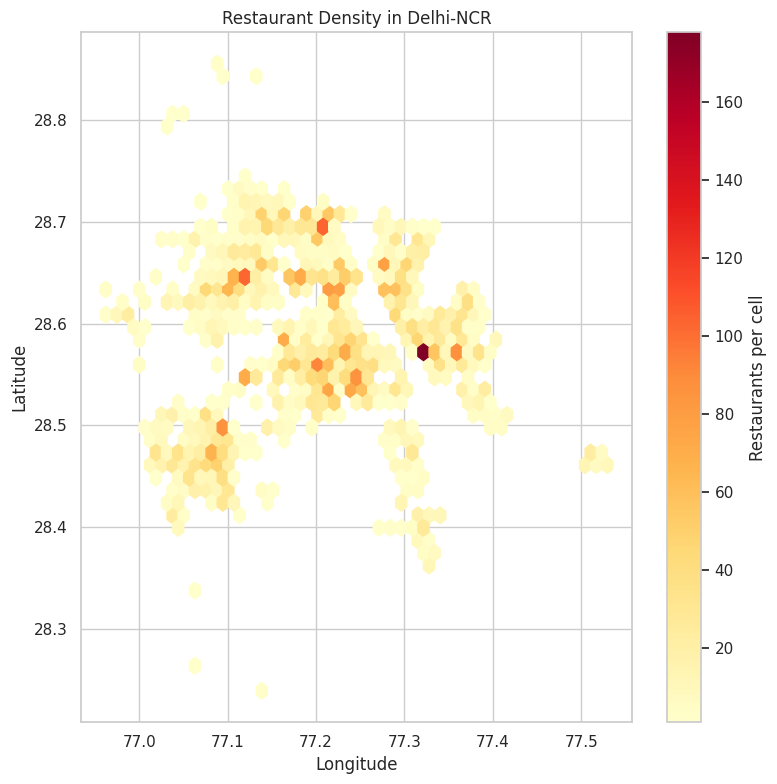

Restaurants plotted: 7549


In [4]:
ncr_cities = ["New Delhi", "Gurgaon", "Noida", "Faridabad", "Ghaziabad"]

ncr_map = map_df[
    map_df["City"].isin(ncr_cities)
    & map_df["Latitude"].between(27.8, 29.0)
    & map_df["Longitude"].between(76.6, 77.8)
]

fig, ax = plt.subplots(figsize=(8, 8))
hb = ax.hexbin(
    ncr_map["Longitude"], ncr_map["Latitude"],
    gridsize=45, cmap="YlOrRd", mincnt=1
)
fig.colorbar(hb, ax=ax, label="Restaurants per cell")
ax.set_title("Restaurant Density in Delhi-NCR")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

print("Restaurants plotted:", len(ncr_map))

## 5. City-Level Analysis

**Purpose:** Compare cities by restaurant count and by average rating.

**Method:** Rating statistics use rated restaurants only. A city needs at least 20 rated restaurants to appear in the rating ranking, so very small samples do not dominate.

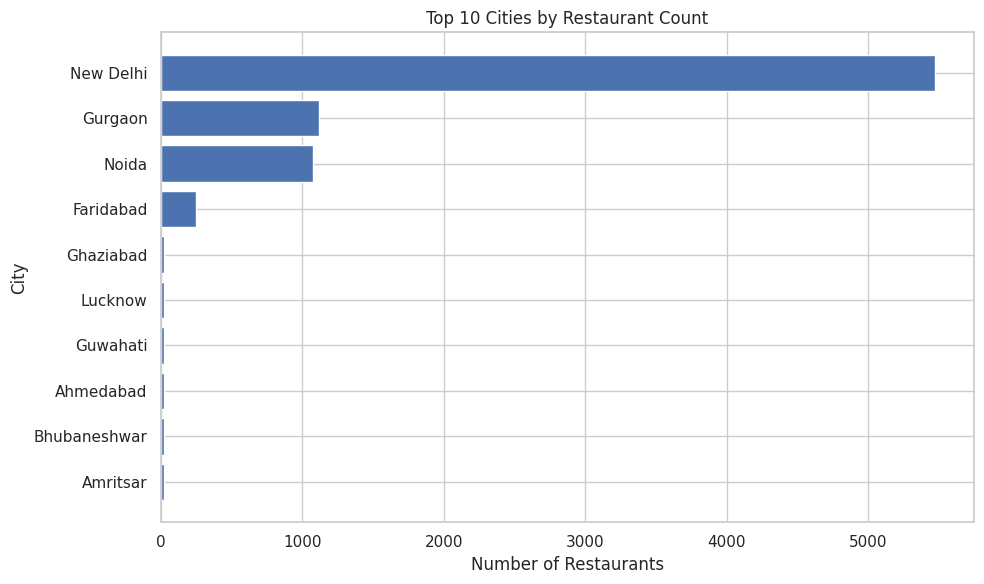

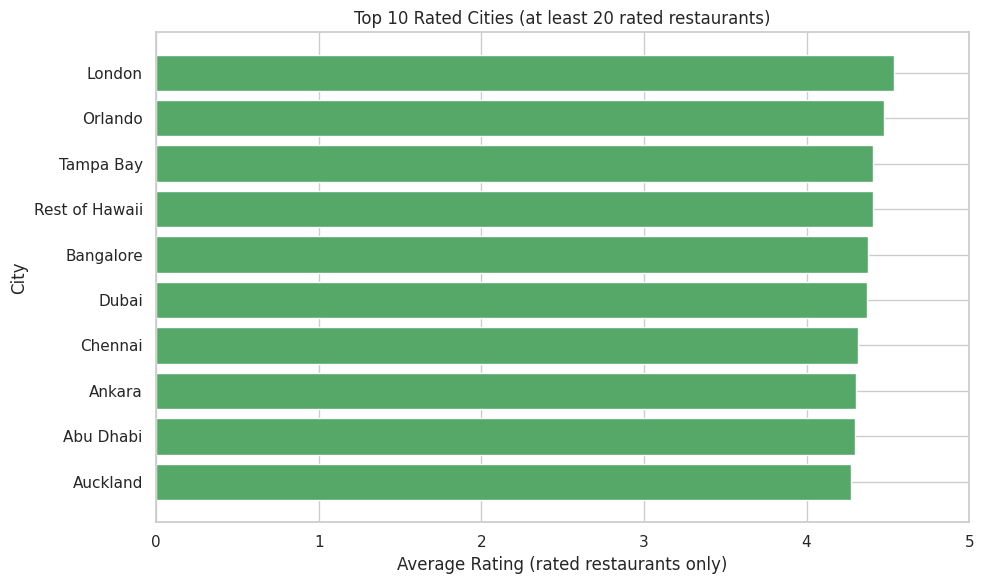

Top cities by restaurant count:


,City,Rated_Restaurants,Average_Rating,Median_Rating,Average_Price_Range,Total_Votes,Restaurant_Count
88,New Delhi,4048,3.30,3.3,1.77,627090,5473
50,Gurgaon,890,3.33,3.3,2.00,131978,1118
89,Noida,696,3.16,3.1,1.77,73148,1080
43,Faridabad,151,3.10,3.0,1.56,6406,251
48,Ghaziabad,23,3.10,3.2,1.87,2365,25
2,Ahmedabad,21,4.16,4.2,2.57,12266,21
5,Amritsar,21,3.69,3.6,1.81,3665,21
17,Bhubaneshwar,21,3.98,4.0,1.86,4243,21
51,Guwahati,21,4.19,4.1,2.52,4964,21
69,Lucknow,21,4.20,4.2,2.57,9130,21



Top-rated eligible cities:


,City,Rated_Restaurants,Average_Rating,Median_Rating,Average_Price_Range,Total_Votes,Restaurant_Count
67,London,20,4.54,4.55,3.00,8724,20
91,Orlando,20,4.47,4.40,2.90,23989,20
110,Rest of Hawaii,20,4.41,4.40,2.35,15055,20
124,Tampa Bay,20,4.41,4.45,2.55,27407,20
14,Bangalore,20,4.38,4.40,2.70,56115,20
39,Dubai,20,4.37,4.40,3.05,18693,20
26,Chennai,20,4.31,4.30,2.45,27695,20
6,Ankara,20,4.30,4.30,2.80,2627,20
0,Abu Dhabi,20,4.30,4.30,3.30,6045,20
9,Auckland,20,4.28,4.35,3.05,6795,20


Note: every city in this ranking has only about 20 rated restaurants, so these averages are far less stable than those of Delhi-NCR.


In [5]:
city_counts = geo_df.groupby("City").size().rename("Restaurant_Count")

city_analysis = (
    rated_df.groupby("City")
    .agg(
        Rated_Restaurants=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean"),
        Median_Rating=("Aggregate rating", "median"),
        Average_Price_Range=("Price range", "mean"),
        Total_Votes=("Votes", "sum"),
    )
    .join(city_counts)
    .reset_index()
)

# 1. Top 10 cities by restaurant count
top_cities_count = city_analysis.nlargest(10, "Restaurant_Count").sort_values("Restaurant_Count")

plt.figure(figsize=(10, 6))
plt.barh(top_cities_count["City"], top_cities_count["Restaurant_Count"], color="#4C72B0")
plt.title("Top 10 Cities by Restaurant Count")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# 2. Top-rated cities (>= 20 rated restaurants)
eligible_cities = city_analysis[city_analysis["Rated_Restaurants"] >= 20]
top_rated_cities = eligible_cities.nlargest(10, "Average_Rating").sort_values("Average_Rating")

plt.figure(figsize=(10, 6))
plt.barh(top_rated_cities["City"], top_rated_cities["Average_Rating"], color="#55A868")
plt.title("Top 10 Rated Cities (at least 20 rated restaurants)")
plt.xlabel("Average Rating (rated restaurants only)")
plt.ylabel("City")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

print("Top cities by restaurant count:")
display(city_analysis.nlargest(10, "Restaurant_Count").round(2))

print("\nTop-rated eligible cities:")
display(top_rated_cities.sort_values("Average_Rating", ascending=False).round(2))
print("Note: every city in this ranking has only about 20 rated restaurants, so these averages are far less stable than those of Delhi-NCR.")

## 6. Cuisine Distribution in Major Cities

**Purpose:** Identify the most common cuisines in New Delhi, Gurgaon, and Noida.

**Method:** Multi-cuisine entries (for example "North Indian, Chinese") are split, so each restaurant is counted once under every cuisine it serves.

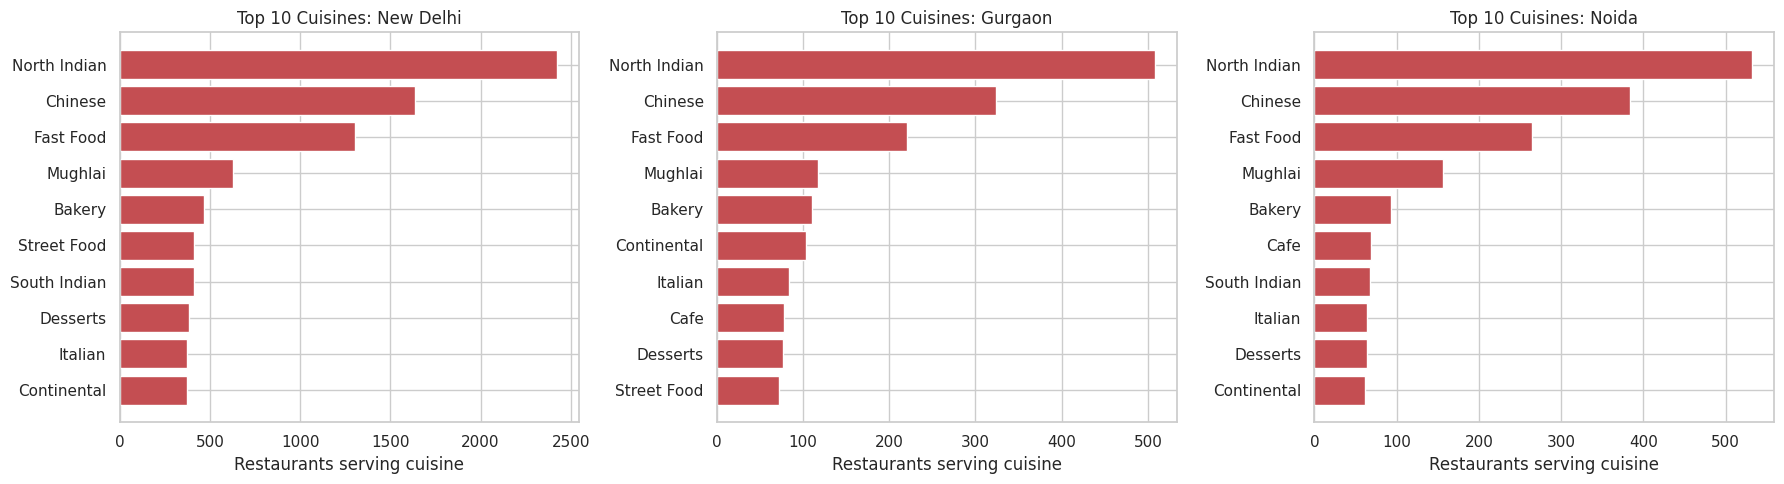


Top 5 cuisines in New Delhi:


,City,Cuisine,Restaurant_Count
0,New Delhi,North Indian,2425
1,New Delhi,Chinese,1638
2,New Delhi,Fast Food,1304
3,New Delhi,Mughlai,628
4,New Delhi,Bakery,465



Top 5 cuisines in Gurgaon:


,City,Cuisine,Restaurant_Count
0,Gurgaon,North Indian,508
1,Gurgaon,Chinese,324
2,Gurgaon,Fast Food,220
3,Gurgaon,Mughlai,117
4,Gurgaon,Bakery,110



Top 5 cuisines in Noida:


,City,Cuisine,Restaurant_Count
0,Noida,North Indian,532
1,Noida,Chinese,384
2,Noida,Fast Food,265
3,Noida,Mughlai,156
4,Noida,Bakery,93


Note: a restaurant with several cuisines is counted once under each cuisine.


In [6]:
major_cities = ["New Delhi", "Gurgaon", "Noida"]

cuisine_city_df = geo_df[geo_df["City"].isin(major_cities) & geo_df["Cuisines"].notna()].copy()
cuisine_city_df["Cuisine"] = cuisine_city_df["Cuisines"].str.split(",")
cuisine_city_df = cuisine_city_df.explode("Cuisine")
cuisine_city_df["Cuisine"] = cuisine_city_df["Cuisine"].str.strip()

cuisine_counts = (
    cuisine_city_df.groupby(["City", "Cuisine"]).size().reset_index(name="Restaurant_Count")
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=False)
for ax, city in zip(axes, major_cities):
    top = (
        cuisine_counts[cuisine_counts["City"] == city]
        .nlargest(10, "Restaurant_Count")
        .sort_values("Restaurant_Count")
    )
    ax.barh(top["Cuisine"], top["Restaurant_Count"], color="#C44E52")
    ax.set_title(f"Top 10 Cuisines: {city}")
    ax.set_xlabel("Restaurants serving cuisine")
plt.tight_layout()
plt.show()

for city in major_cities:
    print(f"\nTop 5 cuisines in {city}:")
    display(
        cuisine_counts[cuisine_counts["City"] == city]
        .nlargest(5, "Restaurant_Count")
        .reset_index(drop=True)
    )
print("Note: a restaurant with several cuisines is counted once under each cuisine.")

## 7. Locality-Level Analysis

**Purpose:** Find the best-rated neighborhoods.

**Method:** Only rated restaurants are used, and a locality needs at least 10 rated restaurants. Error bars show an approximate 95% confidence interval (1.96 x standard deviation / sqrt(n)), so small samples are visible.

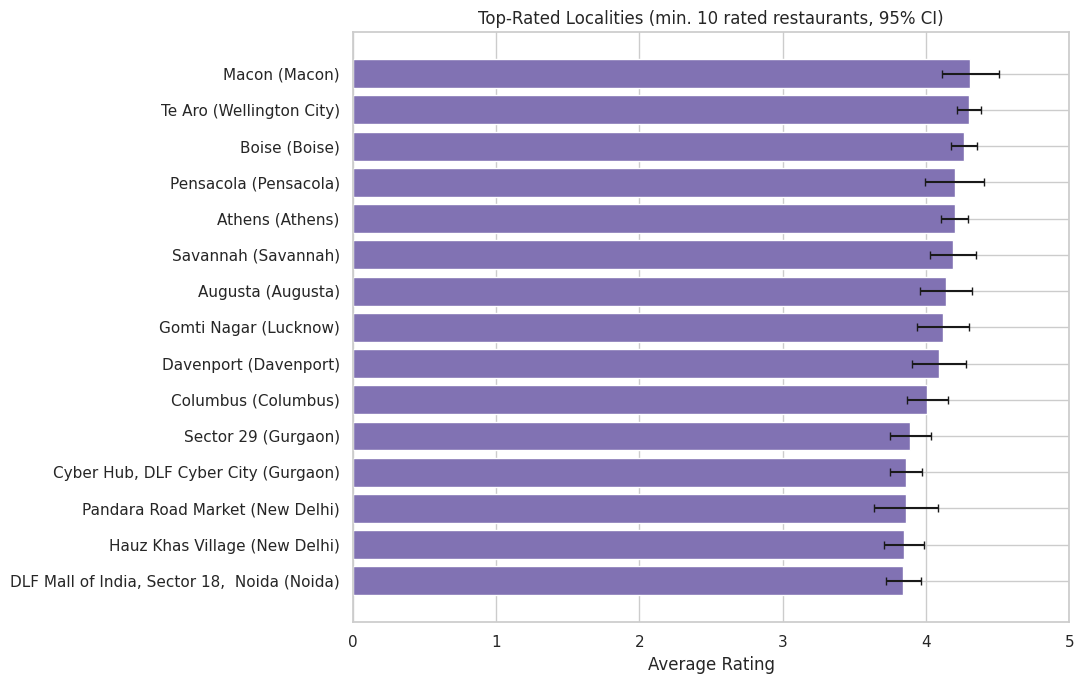

,City,Locality,Rated_Restaurants,Average_Rating,Rating_Std,Average_Price_Range,Total_Votes,CI_95
592,Macon,Macon,10,4.31,0.32,2.30,2972,0.20
1213,Wellington City,Te Aro,15,4.30,0.17,3.13,2184,0.09
139,Boise,Boise,18,4.27,0.20,2.00,9525,0.09
62,Athens,Athens,20,4.20,0.22,1.60,12750,0.09
1011,Pensacola,Pensacola,12,4.20,0.36,2.25,10585,0.20
1099,Savannah,Savannah,18,4.19,0.34,2.39,14185,0.16
78,Augusta,Augusta,15,4.14,0.35,2.27,6406,0.18
570,Lucknow,Gomti Nagar,12,4.12,0.32,2.50,3910,0.18
221,Davenport,Davenport,13,4.09,0.35,2.00,2305,0.19
210,Columbus,Columbus,19,4.01,0.31,2.11,5152,0.14


In [7]:
locality_analysis = (
    rated_df.dropna(subset=["Locality"])
    .groupby(["City", "Locality"])
    .agg(
        Rated_Restaurants=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean"),
        Rating_Std=("Aggregate rating", "std"),
        Average_Price_Range=("Price range", "mean"),
        Total_Votes=("Votes", "sum"),
    )
    .reset_index()
)
locality_analysis["CI_95"] = 1.96 * locality_analysis["Rating_Std"] / np.sqrt(locality_analysis["Rated_Restaurants"])

eligible_localities = locality_analysis[locality_analysis["Rated_Restaurants"] >= 10].copy()
top_localities = eligible_localities.nlargest(15, "Average_Rating").sort_values("Average_Rating")

labels = top_localities["Locality"] + " (" + top_localities["City"] + ")"
plt.figure(figsize=(11, 7))
plt.barh(labels, top_localities["Average_Rating"], xerr=top_localities["CI_95"], color="#8172B3", capsize=3)
plt.title("Top-Rated Localities (min. 10 rated restaurants, 95% CI)")
plt.xlabel("Average Rating")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

display(top_localities.sort_values("Average_Rating", ascending=False).round(2))

## 8. Delhi-NCR Locality Comparison

**Purpose:** Repeat the locality analysis for Delhi-NCR only, where the data is dense enough for reliable comparisons.

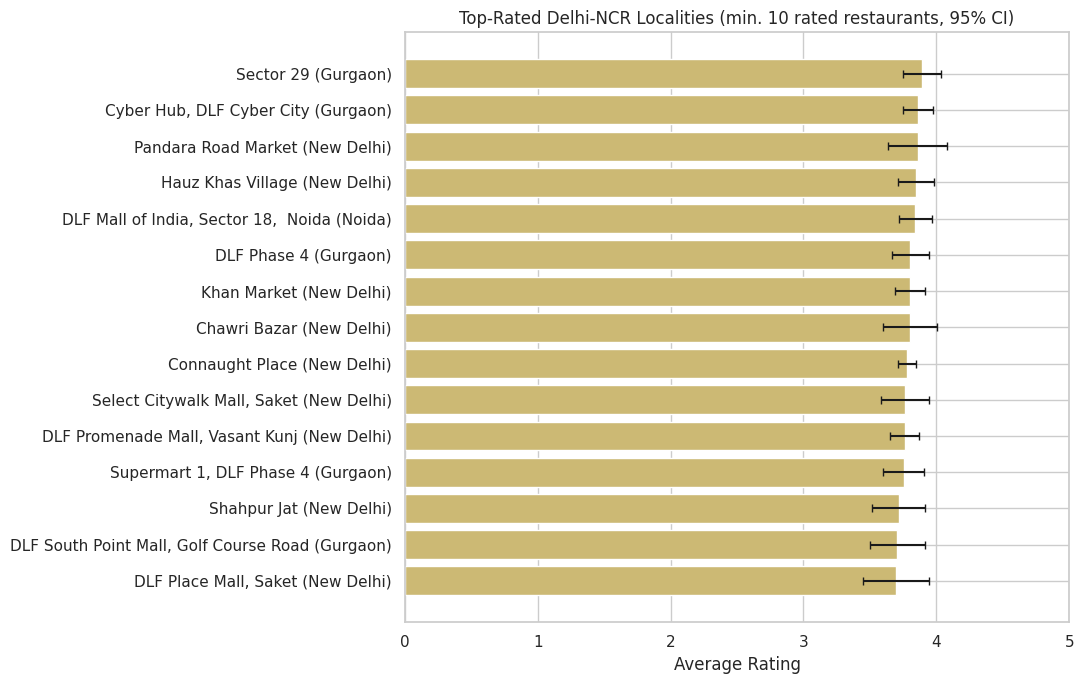

Eligible NCR localities: 159


,City,Locality,Rated_Restaurants,Average_Rating,Rating_Std,Average_Price_Range,Total_Votes,CI_95
413,Gurgaon,Sector 29,38,3.89,0.45,2.87,20881,0.14
356,Gurgaon,"Cyber Hub, DLF Cyber City",41,3.86,0.36,2.80,36185,0.11
818,New Delhi,Pandara Road Market,10,3.86,0.36,2.40,7978,0.22
733,New Delhi,Hauz Khas Village,24,3.85,0.35,2.79,32573,0.14
908,Noida,"DLF Mall of India, Sector 18, Noida",31,3.84,0.35,2.23,8277,0.12
363,Gurgaon,DLF Phase 4,21,3.80,0.32,2.19,3414,0.14
767,New Delhi,Khan Market,43,3.80,0.38,2.74,28463,0.11
688,New Delhi,Chawri Bazar,12,3.80,0.36,1.00,1410,0.20
695,New Delhi,Connaught Place,119,3.78,0.37,2.63,128107,0.07
849,New Delhi,"Select Citywalk Mall, Saket",25,3.76,0.46,2.20,9054,0.18


In [8]:
ncr_localities = locality_analysis[
    locality_analysis["City"].isin(ncr_cities) & (locality_analysis["Rated_Restaurants"] >= 10)
].copy()

top_ncr = ncr_localities.nlargest(15, "Average_Rating").sort_values("Average_Rating")
labels = top_ncr["Locality"] + " (" + top_ncr["City"] + ")"

plt.figure(figsize=(11, 7))
plt.barh(labels, top_ncr["Average_Rating"], xerr=top_ncr["CI_95"], color="#CCB974", capsize=3)
plt.title("Top-Rated Delhi-NCR Localities (min. 10 rated restaurants, 95% CI)")
plt.xlabel("Average Rating")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

print("Eligible NCR localities:", len(ncr_localities))
display(top_ncr.sort_values("Average_Rating", ascending=False).round(2))

## 9. Price Range and Ratings

**Purpose:** Measure how price range relates to ratings.

**Method:** The first table compares averages with and without unrated restaurants to show why they must be excluded. The rest of the section uses rated restaurants only, with both Pearson and Spearman correlations.

Effect of including unrated (0) restaurants:


,Price range,Average_Rating (incl. unrated),Restaurants,Average_Rating (rated only),Median_Rating
0,1,2.00,2744,3.24,3.2
1,2,2.94,2711,3.38,3.4
2,3,3.68,1373,3.78,3.8
3,4,3.82,575,3.89,3.9



Rated restaurants by price range:


,Price range,Restaurants,Average_Rating,Median_Rating,Average_Votes
0,1,2744,3.24,3.2,71.71
1,2,2711,3.38,3.4,169.35
2,3,1373,3.78,3.8,455.14
3,4,575,3.89,3.9,375.62


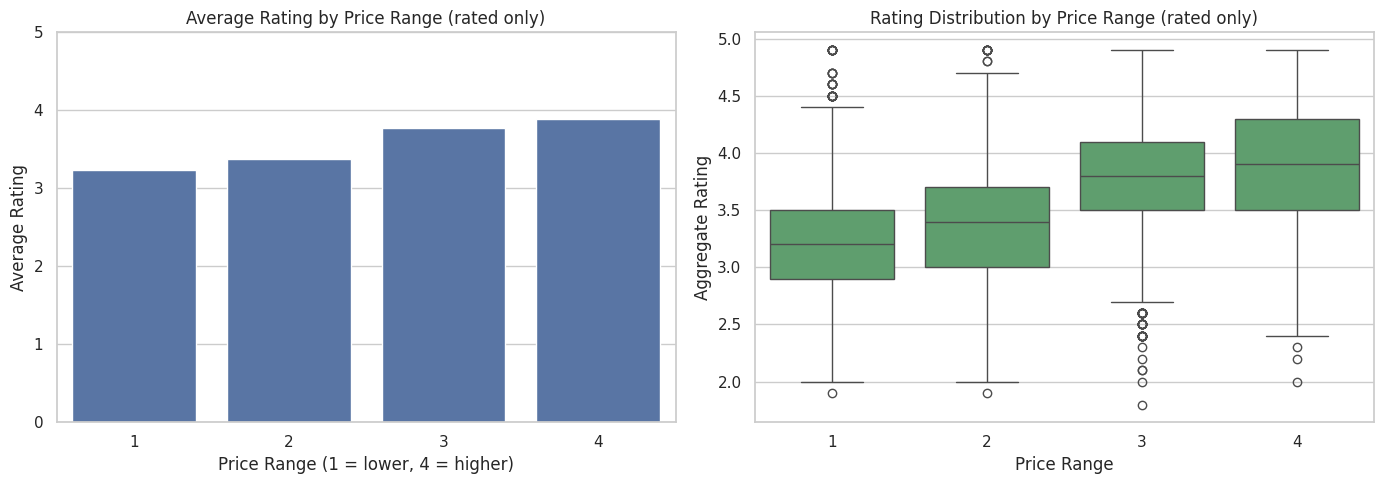

Correlation between price range and rating (rated only): Pearson = 0.403, Spearman = 0.402


In [9]:
def price_summary(data):
    return (
        data.groupby("Price range")
        .agg(
            Restaurants=("Restaurant ID", "count"),
            Average_Rating=("Aggregate rating", "mean"),
            Median_Rating=("Aggregate rating", "median"),
            Average_Votes=("Votes", "mean"),
        )
        .reset_index()
    )

with_zeros = price_summary(geo_df)
rated_only = price_summary(rated_df)

comparison = with_zeros[["Price range", "Average_Rating"]].merge(
    rated_only[["Price range", "Restaurants", "Average_Rating", "Median_Rating"]],
    on="Price range", suffixes=(" (incl. unrated)", " (rated only)")
)
print("Effect of including unrated (0) restaurants:")
display(comparison.round(2))

print("\nRated restaurants by price range:")
display(rated_only.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=rated_only, x="Price range", y="Average_Rating", color="#4C72B0", ax=axes[0])
axes[0].set_title("Average Rating by Price Range (rated only)")
axes[0].set_xlabel("Price Range (1 = lower, 4 = higher)")
axes[0].set_ylabel("Average Rating")
axes[0].set_ylim(0, 5)

sns.boxplot(data=rated_df, x="Price range", y="Aggregate rating", color="#55A868", ax=axes[1])
axes[1].set_title("Rating Distribution by Price Range (rated only)")
axes[1].set_xlabel("Price Range")
axes[1].set_ylabel("Aggregate Rating")
plt.tight_layout()
plt.show()

pearson = rated_df[["Price range", "Aggregate rating"]].corr().iloc[0, 1]
spearman = rated_df[["Price range", "Aggregate rating"]].corr(method="spearman").iloc[0, 1]
print(f"Correlation between price range and rating (rated only): Pearson = {pearson:.3f}, Spearman = {spearman:.3f}")

## 10. Summary Statistics and Conclusion

**Purpose:** Recompute the headline numbers from the data, so every figure in the conclusion can be verified.

In [10]:
total = len(geo_df)
top3_share = geo_df["City"].isin(["New Delhi", "Gurgaon", "Noida"]).mean() * 100
best = ncr_localities.sort_values("Average_Rating", ascending=False).iloc[0]

print(f"Total restaurants: {total:,} across {geo_df['City'].nunique()} cities")
print(f"New Delhi: {int((geo_df['City'] == 'New Delhi').sum()):,}")
print(f"New Delhi + Gurgaon + Noida share: {top3_share:.1f}%")
print(f"Placeholder (0, 0) coordinates: {int(zero_mask.sum())}")
print(f"Unrated restaurants: {int((~geo_df['Is_Rated']).sum()):,}")
print(f"Best NCR locality: {best['Locality']} ({best['City']}), avg {best['Average_Rating']:.2f}, {int(best['Rated_Restaurants'])} rated restaurants")
print(f"Price range avg rating (rated only): " +
      ", ".join(f"{int(r['Price range'])}: {r['Average_Rating']:.2f}" for _, r in rated_only.iterrows()))

Total restaurants: 9,551 across 141 cities
New Delhi: 5,473
New Delhi + Gurgaon + Noida share: 80.3%
Placeholder (0, 0) coordinates: 497
Unrated restaurants: 2,148
Best NCR locality: Sector 29 (Gurgaon), avg 3.89, 38 rated restaurants
Price range avg rating (rated only): 1: 3.24, 2: 3.38, 3: 3.78, 4: 3.89


## Conclusion and Insights

## Key Findings

1. **Geographical concentration:** The dataset contains 9,551 restaurants across 141 cities, with 5,473 in New Delhi. New Delhi, Gurgaon, and Noida together account for about 80.3% of all records.
2. **Cuisine preferences:** North Indian, Chinese, and Fast Food are the three most common cuisines in New Delhi, Gurgaon, and Noida. Mughlai and Bakery follow in all three.
3. **Locality-level ratings:** Among Delhi-NCR localities with at least 10 rated restaurants, Sector 29 in Gurgaon has the highest average rating (3.89, from 38 rated restaurants). Cyber Hub (3.86, 41 restaurants) is almost level with it, and the confidence intervals overlap, so the ranking among the top few localities is not decisive.
4. **Price and ratings:** Among rated restaurants, the average rating rises from 3.24 in price range 1 to 3.89 in price range 4 (Pearson r = 0.40, Spearman r = 0.40). This is a moderate positive association. Including the 2,148 unrated restaurants (rating 0) would wrongly show a much steeper rise (2.00 to 3.82).
5. **Geographical data quality:** No coordinates are missing or outside the valid range, but 497 restaurants have placeholder coordinates of (0, 0). They were excluded from all maps, leaving 9,054 usable locations.

## Limitations

- The dataset is heavily concentrated in Delhi-NCR, so results do not represent all cities equally.
- The top-rated cities each have only about 20 rated restaurants, and many top localities have 10 to 25, so their averages are less stable.
- 2,148 restaurants (about 22%) are unrated and were excluded from rating comparisons.
- Ratings depend on factors beyond location and price, such as cuisine, service, and the number of reviewers.
- The analysis shows associations, not causal relationships.

### Conclusion

This project explores restaurant distribution, cuisine concentration, locality-level ratings, and price-range patterns using geographical analysis. The data is strongly concentrated in Delhi-NCR, with similar cuisine preferences across its major cities. Higher price ranges are moderately associated with higher ratings once unrated restaurants are removed. Cleaning the placeholder coordinates and the unrated records was essential for accurate maps and fair comparisons.

## Future Improvements

1. Add an interactive city and locality filter dashboard.
2. Build an interactive density map (for example with folium) of Delhi-NCR clusters.
3. Compare ratings while controlling for cuisine and price range, for example with regression.
4. Use vote counts to weight ratings, so that localities with few reviews count for less.
